# SVM com kernel RBF — previsão do escalão etário (`AGE_RANGE`)

**DAA 2026/2027 — Tarefa de competição (Kaggle, métrica: Macro F1-Score)**

1. Funções de pré-processamento, modelo e avaliação
2. Dados e partição treino / holdout
3. Estrutura do pré-processamento: escala das dummies e filtro de redundância
4. Otimização de hiperparâmetros (grelha alargada, incluindo `class_weight`)
5. Seleção do modelo (validação cruzada repetida e afinação fina)
6. Ablação: contributo de cada componente (diferenças emparelhadas)
7. Efeito dos pesos das classes por classe
8. Avaliação final no holdout (intervalos de confiança por bootstrap)
9. Modelo final e submissão Kaggle
10. Conclusões

Regras:
* O **holdout (20%)** é separado antes de qualquer decisão sobre os dados (incluindo a deteção do tipo
  das colunas) e não é usado para escolher hiperparâmetros.
* Tudo o que aprende com os dados (imputação, escala, codificação, filtros e seleção de features)
  está dentro de um `Pipeline` e é reajustado em cada fold.
* Todas as comparações no holdout têm intervalo de confiança a 95% por bootstrap; as comparações entre
  modelos usam diferenças **emparelhadas** (mesmas reamostragens / mesmos folds).
* O CV do modelo escolhido numa grelha é otimista (é o máximo de muitas estimativas com ruído); a estimativa
  honesta do desempenho é a do **holdout**.

In [1]:
import os, re, time, hashlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import BaseEstimator, ClassifierMixin, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import SelectKBest, VarianceThreshold, f_classif
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, classification_report, f1_score
from sklearn.model_selection import (GridSearchCV, RepeatedStratifiedKFold, StratifiedKFold, cross_validate,
                                     learning_curve, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC

warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.max_columns", 40)
plt.rcParams["figure.dpi"] = 110

RANDOM_STATE = 42
N_JOBS = -1
TRAIN_PATH = "dataset_train.csv"
TEST_PATH = "dataset_test_X.csv"
SAMPLE_SUB_PATH = "example_submission_10.csv"   # ficheiro de exemplo da competição

## 1. Funções

### 1.1 Pré-processamento

* Colunas numéricas guardadas como texto são convertidas para número; os códigos de não-resposta
  (`"Não aplicável"`, `"Sem resposta"`, …) passam a `NaN` (imputado pela mediana) e o motivo fica numa
  coluna categórica `__status`.
* `PE7` está no formato HHMM (`"0130"` = 1h30). A conversão passa primeiro por `int(float(v))`, para
  funcionar também se o valor vier como `"130.0"`, e só depois aplica `zfill(4)`.
* Restantes colunas → one-hot (categorias com < 20 ocorrências agrupadas).

In [2]:
TARGET = "AGE_RANGE"
DROP_COLS = ["PID", "HHID", "PROXY", "COUNTRY"]          # identificadores e constantes
MISSING_CODES = {"Não aplicável", "Sem resposta", "Nunca", "Há mais de 1 ano",
                 "Gravidez sem termo (n.a.)"}
FORCE_CATEGORICAL = {"PA1"}                                # mistura AAAA, AAAAMM e texto
_TOP_CODE = re.compile(r"^\s*(?:>=\s*)?(\d+(?:\.\d+)?)\s*(?:ou mais)?\s*$")


def _to_number(v):
    if pd.isna(v) or v in MISSING_CODES:
        return np.nan
    if isinstance(v, (int, float)):
        return float(v)
    m = _TOP_CODE.match(str(v))
    return float(m.group(1)) if m else np.nan


def hhmm_to_minutes(v):
    # "0130" -> 90 ; "130.0" -> 90 ; "1230" -> 750
    if pd.isna(v) or v in MISSING_CODES:
        return np.nan
    try:
        s = str(int(float(v))).zfill(4)
    except (TypeError, ValueError):
        return np.nan
    h, m = int(s[:-2]), int(s[-2:])
    return h * 60 + m if m < 60 else np.nan


def detect_numeric_columns(df, min_numeric_share=0.9, min_unique=5):
    # Numérica se >= 90% dos valores respondidos forem números e houver >= 5 valores distintos
    numeric = []
    for c in df.columns:
        if c in FORCE_CATEGORICAL:
            continue
        s = df[c]
        if pd.api.types.is_numeric_dtype(s):
            numeric.append(c)
            continue
        answered = s[~s.isin(MISSING_CODES) & s.notna()]
        if len(answered) == 0:
            continue
        conv = answered.map(_to_number)
        if conv.notna().mean() >= min_numeric_share and conv.nunique() >= min_unique:
            numeric.append(c)
    return numeric


def clean(df, numeric_cols):
    # Limpeza determinística (não aprende nada com os dados)
    df = df.drop(columns=[c for c in DROP_COLS + [TARGET] if c in df.columns]).copy()
    out = {}
    for c in df.columns:
        if c in numeric_cols:
            raw = df[c]
            val = raw.map(hhmm_to_minutes) if c == "PE7" else raw.map(_to_number)
            out[c] = val.astype(float)
            if not pd.api.types.is_numeric_dtype(raw):
                out[c + "__status"] = raw.where(raw.isin(MISSING_CODES), "valor").astype(str)
        else:
            out[c] = df[c].astype(str)
    return pd.DataFrame(out, index=df.index)


def split_types(X_clean):
    num = [c for c in X_clean.columns if pd.api.types.is_float_dtype(X_clean[c])]
    return num, [c for c in X_clean.columns if c not in num]


def build_preprocessor(X_clean, min_frequency=20):
    num, cat = split_types(X_clean)
    num_pipe = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())])
    cat_pipe = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=min_frequency,
                             sparse_output=False)
    return ColumnTransformer([("num", num_pipe, num), ("cat", cat_pipe, cat)])

### 1.2 Filtro de redundância, SVM e métricas

* **`CorrelationFilter`** — ordena as features pelo F-score ANOVA e percorre-as por essa ordem,
  descartando cada uma cuja correlação absoluta com uma feature já mantida exceda o limiar. Corre
  **antes** do `SelectKBest`, para que as `k` vagas não sejam gastas em cópias quase perfeitas da
  mesma informação (p.ex. os vários "Não aplicável" do bloco `PC1A…E` / `HA1A…G`), o que também
  evita multiplicar o peso dessa informação na distância RBF.
* **`RBFSVC`** — `SVC` RBF com `gamma = gamma_mult / (n_features · Var(X))` (o mesmo `gamma_mult` tem
  significado comparável para qualquer `k`) e `class_weight` que aceita, além de `None` e
  `"balanced"` (∝ 1/freq), `"sqrt"` (∝ 1/√freq). Os pesos são normalizados como no `"balanced"`
  (soma dos pesos das amostras = n), para que `C` tenha a mesma escala nas três opções.
  Usa `break_ties=True`: a previsão é a classe com maior função de decisão (votos *one-vs-one* + confiança).
  O voto simples do `libsvm` resolveria os empates (≈ 4% dos casos) a favor do escalão de **índice mais
  baixo**, deslocando previsões para o escalão de baixo entre vizinhos (p.ex. 12 em vez de 13).
* **`nb_se`** — erro-padrão da média de *J* scores de CV com a **correção de Nadeau & Bengio**:
  `sqrt((1/J + n_teste/n_treino) · s²)`. Os folds partilham dados de treino e não são independentes; o
  `s/√J` simples subestima a incerteza (com 3 folds × 3 repetições, cerca de 2.35×).

In [3]:
class CorrelationFilter(TransformerMixin, BaseEstimator):
    def __init__(self, threshold=None):
        self.threshold = threshold

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        p = X.shape[1]
        if self.threshold is None:
            self.support_ = np.ones(p, dtype=bool)
            return self
        F, _ = f_classif(X, y)
        F = np.nan_to_num(F, nan=0.0, posinf=np.finfo(float).max)
        order = np.argsort(-F, kind="stable")
        corr = np.abs(np.corrcoef(X, rowvar=False))
        corr = np.nan_to_num(corr, nan=0.0)
        keep = []
        for j in order:
            if not keep or corr[j, keep].max() <= self.threshold:
                keep.append(j)
        self.support_ = np.zeros(p, dtype=bool)
        self.support_[keep] = True
        return self

    def transform(self, X):
        return np.asarray(X, dtype=float)[:, self.support_]


def class_weights(y, mode):
    if mode in (None, "balanced"):
        return mode
    classes, counts = np.unique(y, return_counts=True)
    if mode == "sqrt":
        w = 1.0 / np.sqrt(counts)
        w *= len(y) / np.sum(w * counts)        # soma dos pesos das amostras = n
        return dict(zip(classes, w))
    raise ValueError(mode)


class RBFSVC(ClassifierMixin, BaseEstimator):
    def __init__(self, C=1.0, gamma_mult=1.0, class_weight=None, cache_size=1000, random_state=None):
        self.C = C
        self.gamma_mult = gamma_mult
        self.class_weight = class_weight
        self.cache_size = cache_size
        self.random_state = random_state

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        var = X.var()
        self.gamma_ = self.gamma_mult / (X.shape[1] * var) if var > 0 else self.gamma_mult
        self.svc_ = SVC(kernel="rbf", C=self.C, gamma=self.gamma_,
                        class_weight=class_weights(np.asarray(y), self.class_weight),
                        break_ties=True, cache_size=self.cache_size, random_state=self.random_state)
        self.svc_.fit(X, y)
        self.classes_ = self.svc_.classes_
        return self

    def predict(self, X):
        return self.svc_.predict(np.asarray(X, dtype=float))

    def decision_function(self, X):
        return self.svc_.decision_function(np.asarray(X, dtype=float))


def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, average="macro")


def nb_se(scores, test_train_ratio=1 / 2):
    # Nadeau & Bengio (2003): variância corrigida (1/J + n_teste/n_treino) * s^2; 3 folds -> ratio = 1/2
    scores = np.asarray(scores, dtype=float)
    return np.sqrt((1 / len(scores) + test_train_ratio) * scores.var(ddof=1))


def bootstrap_ci(y_true, y_pred, n_boot=1000, seed=RANDOM_STATE):
    # IC 95% do Macro F1 por bootstrap estratificado do holdout
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    rng = np.random.default_rng(seed)
    idx_by_class = [np.where(y_true == c)[0] for c in np.unique(y_true)]
    stats = []
    for _ in range(n_boot):
        idx = np.concatenate([rng.choice(ix, len(ix), replace=True) for ix in idx_by_class])
        stats.append(macro_f1(y_true[idx], y_pred[idx]))
    lo, hi = np.percentile(stats, [2.5, 97.5])
    return macro_f1(y_true, y_pred), lo, hi


def bootstrap_diff(y_true, pred_a, pred_b, n_boot=1000, seed=RANDOM_STATE):
    # Diferença emparelhada Macro F1(a) − Macro F1(b) nas mesmas reamostragens
    y_true, pred_a, pred_b = map(np.asarray, (y_true, pred_a, pred_b))
    rng = np.random.default_rng(seed)
    idx_by_class = [np.where(y_true == c)[0] for c in np.unique(y_true)]
    d = []
    for _ in range(n_boot):
        idx = np.concatenate([rng.choice(ix, len(ix), replace=True) for ix in idx_by_class])
        d.append(macro_f1(y_true[idx], pred_a[idx]) - macro_f1(y_true[idx], pred_b[idx]))
    lo, hi = np.percentile(d, [2.5, 97.5])
    return macro_f1(y_true, pred_a) - macro_f1(y_true, pred_b), lo, hi


def fmt_ci(t):
    return f"{t[0]:.4f} [{t[1]:.4f}, {t[2]:.4f}]"

## 2. Dados e partição treino / holdout

In [4]:
train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)
y = train[TARGET]
print("treino:", train.shape, "| teste Kaggle:", test.shape)
print("Distribuição de AGE_RANGE:", y.value_counts().sort_index().to_dict())

idx_tr, idx_ho = train_test_split(train.index, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
y_tr, y_ho = y.loc[idx_tr], y.loc[idx_ho]
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)                  # grelha
cv_rep = RepeatedStratifiedKFold(n_splits=3, n_repeats=3, random_state=RANDOM_STATE)      # decisões finas
print(len(idx_tr), "linhas treino/CV |", len(idx_ho), "linhas holdout")

# Tipo das colunas decidido só com a parte de treino (o holdout não influencia nenhuma decisão)
num_cols = detect_numeric_columns(train.loc[idx_tr].drop(columns=DROP_COLS + [TARGET]))
X_all = clean(train, num_cols)
X_tr, X_ho = X_all.loc[idx_tr], X_all.loc[idx_ho]
print(len(num_cols), "colunas numéricas:", num_cols)

treino: (10962, 237) | teste Kaggle: (3655, 236)
Distribuição de AGE_RANGE: {0: 207, 1: 172, 2: 399, 3: 377, 4: 449, 5: 647, 6: 859, 7: 862, 8: 905, 9: 1014, 10: 1062, 11: 1040, 12: 1000, 13: 823, 14: 650, 15: 496}
8769 linhas treino/CV | 2193 linhas holdout


32 colunas numéricas: ['REFYEAR', 'REFMONTH', 'IN2', 'IN3', 'IN4', 'HHNBPERS_COD', 'HH_ACT', 'HH_INACT', 'HO12_COD', 'HO34_COD', 'AM3', 'AM5', 'IN24', 'IN25', 'IN26', 'BM1', 'BM2', 'PE2', 'PE4', 'PE6', 'PE7', 'PE8', 'PE9', 'DH2', 'DH4', 'SK2', 'IN45', 'IN47', 'IN55', 'IN56', 'IN57', 'IN59']


**Nota sobre o holdout.** A partição (`random_state=42`) é a mesma usada nas explorações preliminares que
fixaram os valores de partida das secções 3 e 4. Essas explorações olharam para o holdout, por isso ele **não
está intocado** e as estimativas no holdout podem ser ligeiramente otimistas. Neste notebook, o holdout não é
usado para nenhuma escolha: serve só de verificação.

In [5]:
# Verificação da conversão do PE7
pe7_raw = train.loc[idx_tr, "PE7"]
answered = ~pe7_raw.isin(MISSING_CODES) & pe7_raw.notna()
print("Valores originais:", pe7_raw.unique()[:10].tolist())
print(f"Respondido no original: {answered.mean():.4f} | numérico após conversão: {X_tr['PE7'].notna().mean():.4f}")
print("Valores respondidos que falharam a conversão:", int((answered & X_tr["PE7"].isna()).sum()))
print("Exemplos:", {v: hhmm_to_minutes(v) for v in ["0130", "1230", "130.0", "0045"]})
print(X_tr["PE7"].describe().round(1).to_dict())

Valores originais: ['Não aplicável', '0200', 'Sem resposta', '0300', '0130', '0035', '0040', '0320', '0100', '0400']
Respondido no original: 0.2665 | numérico após conversão: 0.2665
Valores respondidos que falharam a conversão: 0
Exemplos: {'0130': 90, '1230': 750, '130.0': 90, '0045': 45}
{'count': 2337.0, 'mean': 195.4, 'std': 202.4, 'min': 10.0, '25%': 70.0, '50%': 120.0, '75%': 240.0, 'max': 1800.0}


## 3. Estrutura do pré-processamento

Duas decisões estruturais, testadas por validação cruzada **repetida** (3 folds × 3 repetições, só treino)
com hiperparâmetros fixos e razoáveis (`k=250`, `C=3`, `gamma=0.5×scale`, `class_weight="sqrt"`), antes da
grelha principal. Como todas as configurações usam os mesmos 9 folds, compara-se cada uma com a de
referência (sem filtro, sem escala) pela **diferença emparelhada** fold a fold (média ± erro-padrão com a
correção de Nadeau & Bengio). Os valores fixos destes hiperparâmetros vêm de explorações preliminares, que não
fazem parte deste notebook.

* **Escala das dummies.** Após o `StandardScaler`, as numéricas têm variância 1, mas uma dummy com
  frequência *p* tem variância *p(1−p)* ≤ 0.25. Na distância RBF as categóricas pesam por isso menos.
  Opção: `StandardScaler` aplicado a **todas** as features selecionadas.
* **Filtro de redundância** (`CorrelationFilter`, |r| > 0.9) antes do `SelectKBest`.

In [6]:
def make_svm(k=250, corr=None, scale_all=False, C=1.0, gamma_mult=1.0, class_weight=None, X_ref=None):
    return Pipeline([
        ("pre", build_preprocessor(X_tr if X_ref is None else X_ref)),
        ("vt", VarianceThreshold(0.0)),
        ("corr", CorrelationFilter(corr)),
        ("sel", SelectKBest(f_classif, k=k)),
        ("scale", StandardScaler() if scale_all else "passthrough"),
        ("svm", RBFSVC(C=C, gamma_mult=gamma_mult, class_weight=class_weight, random_state=RANDOM_STATE)),
    ])

A = build_preprocessor(X_tr).fit_transform(X_tr)
n_num = len(split_types(X_tr)[0])
print(f"Variância média: numéricas = {A[:, :n_num].var(0).mean():.3f} | dummies = {A[:, n_num:].var(0).mean():.3f}")

rows, fold_scores = [], {}
for corr in [None, 0.9]:
    for scale_all in [False, True]:
        t = time.time()
        r = cross_validate(make_svm(k=250, corr=corr, scale_all=scale_all, C=3, gamma_mult=0.5, class_weight="sqrt"),
                           X_tr, y_tr, cv=cv_rep, scoring="f1_macro", n_jobs=N_JOBS)
        fold_scores[(corr, scale_all)] = r["test_score"]
        rows.append({"filtro_corr": corr, "escala_dummies": scale_all,
                     "CV": r["test_score"].mean(), "CV_std": r["test_score"].std(), "tempo_s": time.time() - t})
ref = fold_scores[(None, False)]
for row in rows:
    d = fold_scores[(row["filtro_corr"], row["escala_dummies"])] - ref
    row["Δ vs referência"] = d.mean()
    row["Δ EP (N&B)"] = nb_se(d) if d.any() else 0.0
struct = pd.DataFrame(rows).sort_values("CV", ascending=False)
display(struct)
STRUCT = {"corr": struct.iloc[0]["filtro_corr"], "scale_all": bool(struct.iloc[0]["escala_dummies"])}
STRUCT["corr"] = None if pd.isna(STRUCT["corr"]) else float(STRUCT["corr"])
print("Estrutura escolhida:", STRUCT)

Variância média: numéricas = 1.000 | dummies = 0.083


,filtro_corr,escala_dummies,CV,CV_std,tempo_s,Δ vs referência,Δ EP (N&B)
2,0.9000,False,0.4569,0.0111,32.5368,0.0029,0.0042
0,NaN,False,0.4540,0.0088,31.5023,0.0000,0.0000
1,NaN,True,0.4446,0.0092,31.7595,-0.0094,0.0059
3,0.9000,True,0.4381,0.0117,36.3183,-0.0159,0.0057


Estrutura escolhida: {'corr': 0.9, 'scale_all': False}


**Leitura.** O filtro de correlação (0.9) sem escalar as dummies tem o melhor CV repetido (0.4569), +0.0029 acima da referência sem filtro, com EP corrigido (Nadeau & Bengio) de 0.0042. A diferença é menor do que um EP: **o filtro não tem efeito demonstrado**. Mantém-se no pipeline como variante equivalente, que reduz features redundantes antes do `SelectKBest`, mas não é um contributo para o desempenho. Escalar também as dummies piora o resultado: −0.0094 (1.6 EP) sem filtro e −0.0159 (2.8 EP) com filtro. Com o `StandardScaler`, as categorias raras ficam com valores grandes e dominam a distância do kernel RBF.

## 4. Otimização de hiperparâmetros — grelha alargada

Grelha (3 folds, Macro F1) com `class_weight="sqrt"` e valores dos dois lados de cada parâmetro. Os intervalos
da grelha vêm de explorações preliminares que **não são reproduzidas neste notebook**. Nelas, `class_weight=None`,
`C=30`, `gamma=0.1` e `k`=todas as features ficaram claramente piores. A exclusão desses valores não é por isso
verificável aqui. A secção 6 mostra o efeito de `None` contra `sqrt` em CV, e a secção 7 no holdout.

| parâmetro | valores |
|---|---|
| `k` (features) | 150, 250 |
| `C` | 1, 3, 10 |
| `gamma` (× scale) | 0.25, 0.5, 1 |
| `class_weight` | `"sqrt"` (∝ 1/√freq) |

`class_weight` fica fixo em `"sqrt"`: as secções 6 e 7 comparam-no com `None` e `"balanced"`.

No fim verifica-se se o melhor valor de cada parâmetro fica numa ponta da grelha; se ficar, a secção 4.1
prolonga-a nessa direção.

In [7]:
GRID = {
    "sel__k": [150, 250],
    "svm__C": [1.0, 3.0, 10.0],
    "svm__gamma_mult": [0.25, 0.5, 1.0],
    "svm__class_weight": ["sqrt"],
}
n_comb = int(np.prod([len(v) for v in GRID.values()]))
print(f"{n_comb} combinações x {cv.get_n_splits()} folds = {n_comb * cv.get_n_splits()} treinos")

# A grelha corre por valor de k; cada bloco fica guardado em disco (grid_cache/),
# para a execução poder ser retomada sem repetir blocos já calculados.
# A chave do cache inclui uma impressão digital do código usado (pré-processamento, filtro, SVM), dos
# dados de treino, da partição, dos folds e da grelha: qualquer alteração invalida os blocos guardados.
def _code_sig(co):
    parts = [co.co_code.hex(), repr(co.co_names), repr(co.co_varnames)]
    parts += [_code_sig(c) if hasattr(c, "co_code") else repr(c) for c in co.co_consts]
    return "|".join(parts)

def fingerprint(*objs):
    h = hashlib.md5()
    for obj in objs:
        if isinstance(obj, type):
            for name, v in sorted(vars(obj).items()):
                if hasattr(v, "__code__"):
                    h.update((name + _code_sig(v.__code__)).encode())
        elif hasattr(obj, "__code__"):
            h.update(_code_sig(obj.__code__).encode())
        else:
            h.update(repr(obj).encode())
    return h.hexdigest()[:12]

with open(TRAIN_PATH, "rb") as f:
    data_md5 = hashlib.md5(f.read()).hexdigest()
code_fp = fingerprint(_to_number, hhmm_to_minutes, detect_numeric_columns, clean, split_types, build_preprocessor,
                      CorrelationFilter, class_weights, RBFSVC, make_svm,
                      sorted(MISSING_CODES), DROP_COLS, sorted(FORCE_CATEGORICAL), _TOP_CODE.pattern,
                      data_md5, RANDOM_STATE, repr(cv), GRID, STRUCT)
os.makedirs("grid_cache", exist_ok=True)
tag = f"corr{STRUCT['corr']}_scale{STRUCT['scale_all']}_{code_fp}"
print("chave do cache:", tag)
parts, t = [], time.time()
for k in GRID["sel__k"]:
    path = f"grid_cache/{tag}_k{k}.csv"
    if os.path.exists(path):
        parts.append(pd.read_csv(path, dtype={"k": str}, keep_default_na=False)); continue
    sub_grid = {**GRID, "sel__k": [k]}
    search = GridSearchCV(make_svm(**STRUCT), sub_grid, cv=cv, scoring="f1_macro",
                          return_train_score=True, n_jobs=N_JOBS, refit=False)
    search.fit(X_tr, y_tr)
    r = pd.DataFrame(search.cv_results_)
    part = pd.DataFrame({
        "k": r["param_sel__k"].astype(str), "C": r["param_svm__C"].astype(float),
        "gamma": r["param_svm__gamma_mult"].astype(float),
        "class_weight": [("None" if v is None or (isinstance(v, float) and np.isnan(v)) else str(v))
                         for v in r["param_svm__class_weight"]],
        "treino": r["mean_train_score"], "CV": r["mean_test_score"], "CV_std": r["std_test_score"],
    })
    part.to_csv(path, index=False)
    parts.append(part)
    print(f"k={k}: {(time.time() - t) / 60:.1f} min", flush=True)
res = pd.concat(parts, ignore_index=True)
for c in ["C", "gamma", "treino", "CV", "CV_std"]:
    res[c] = res[c].astype(float)
res["CV_se"] = res["CV_std"] / np.sqrt(cv.get_n_splits())
res["k_num"] = res["k"].replace("all", np.inf).astype(float)
res.to_csv("grid_search_svm.csv", index=False)
res.sort_values("CV", ascending=False).head(15)

18 combinações x 3 folds = 54 treinos
chave do cache: corr0.9_scaleFalse_42b2190970ab


,k,C,gamma,class_weight,treino,CV,CV_std,CV_se,k_num
13,250,3.0000,0.5000,sqrt,0.7542,0.4619,0.0121,0.0070,250.0000
14,250,3.0000,1.0000,sqrt,0.9245,0.4613,0.0061,0.0035,250.0000
16,250,10.0000,0.5000,sqrt,0.9273,0.4603,0.0052,0.0030,250.0000
12,250,3.0000,0.2500,sqrt,0.6391,0.4577,0.0061,0.0035,250.0000
6,150,10.0000,0.2500,sqrt,0.6907,0.4569,0.0021,0.0012,150.0000
5,150,3.0000,1.0000,sqrt,0.8467,0.4568,0.0038,0.0022,150.0000
4,150,3.0000,0.5000,sqrt,0.6918,0.4563,0.0055,0.0032,150.0000
2,150,1.0000,1.0000,sqrt,0.6808,0.4559,0.0017,0.0010,150.0000
15,250,10.0000,0.2500,sqrt,0.7575,0.4557,0.0069,0.0040,250.0000
7,150,10.0000,0.5000,sqrt,0.8454,0.4537,0.0062,0.0036,150.0000


Melhor CV: 0.4619 ± 0.0070 (erro-padrão) | treino 0.7542
{'k': '250', 'C': 3.0, 'gamma': 0.5, 'class_weight': 'sqrt'}

Posição do melhor valor de cada parâmetro na grelha:
  k      = 250    -> PONTA da grelha
  C      = 3.0    -> interior
  gamma  = 0.5    -> interior


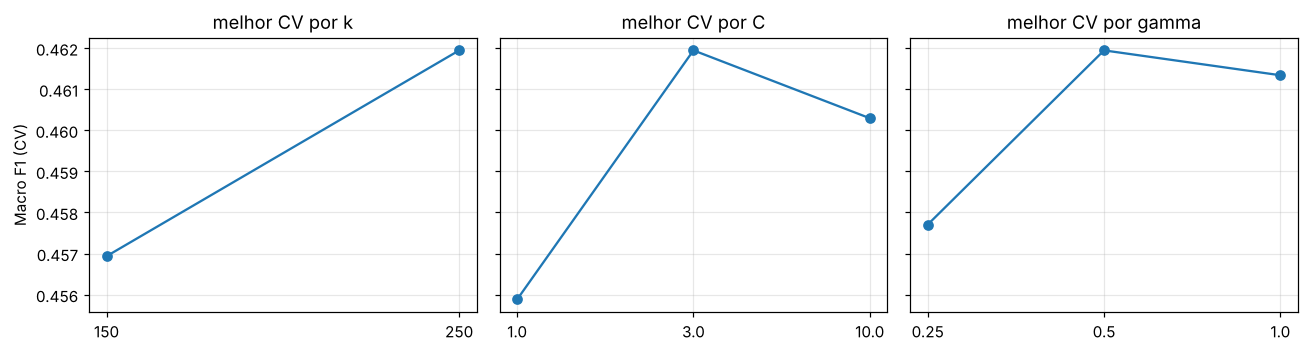

In [8]:
best = res.loc[res["CV"].idxmax()]
print(f"Melhor CV: {best['CV']:.4f} ± {best['CV_se']:.4f} (erro-padrão) | treino {best['treino']:.4f}")
print(best[["k", "C", "gamma", "class_weight"]].to_dict())

print("\nPosição do melhor valor de cada parâmetro na grelha:")
for col, values in [("k", [str(v) for v in GRID["sel__k"]]), ("C", GRID["svm__C"]), ("gamma", GRID["svm__gamma_mult"])]:
    v = best[col]
    pos = values.index(v)
    if v == "all":
        note = "todas as features (limite natural da grelha)"
    elif pos in (0, len(values) - 1):
        note = "PONTA da grelha"
    else:
        note = "interior"
    print(f"  {col:6s} = {v!s:6s} -> {note}")

# Melhor CV por valor de cada parâmetro (máximo sobre os restantes)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.3), sharey=True)
for ax, col, order in [(axes[0], "k", [str(v) for v in GRID["sel__k"]]), (axes[1], "C", GRID["svm__C"]),
                       (axes[2], "gamma", GRID["svm__gamma_mult"])]:
    s = res.groupby(col)["CV"].max().reindex(order)
    ax.plot([str(o) for o in order], s.values, "o-")
    ax.set_title(f"melhor CV por {col}"); ax.grid(alpha=.3)
axes[0].set_ylabel("Macro F1 (CV)")
plt.tight_layout(); plt.show()

### 4.1 Extensão da grelha nas pontas

Se o melhor valor de `C`, `gamma` ou `k` ficar numa ponta da grelha, a grelha é prolongada nessa direção
(`C` ×3 ou ÷3, `gamma` ×2 ou ÷2, `k` −50 ou +200) à volta da melhor combinação. O processo repete-se até o ótimo
ficar no interior, num máximo de 4 iterações. As combinações novas juntam-se a `res`.

In [9]:
EXT_PATH = f"grid_cache/{tag}_extensao.csv"
ext = pd.read_csv(EXT_PATH, dtype={"k": str}, keep_default_na=False) if os.path.exists(EXT_PATH) else pd.DataFrame()

def eval_combo(k, C, gamma, cw):
    global ext
    key = (str(k), float(C), float(gamma), cw)
    if len(ext):
        hit = ext[(ext["k"] == key[0]) & np.isclose(ext["C"].astype(float), key[1])
                  & np.isclose(ext["gamma"].astype(float), key[2]) & (ext["class_weight"] == cw)]
        if len(hit): return hit.iloc[0].to_dict()
    r = cross_validate(make_svm(**STRUCT, k=k, C=C, gamma_mult=gamma, class_weight=None if cw == "None" else cw),
                       X_tr, y_tr, cv=cv, scoring="f1_macro", return_train_score=True, n_jobs=N_JOBS)
    row = {"k": str(k), "C": float(C), "gamma": float(gamma), "class_weight": cw,
           "treino": r["train_score"].mean(), "CV": r["test_score"].mean(), "CV_std": r["test_score"].std()}
    ext = pd.concat([ext, pd.DataFrame([row])], ignore_index=True); ext.to_csv(EXT_PATH, index=False)
    return row

def edge_moves(best, res):
    # novos valores a testar para cada parâmetro cujo ótimo está numa ponta dos valores já avaliados
    moves = {}
    same = res[(res["class_weight"] == best["class_weight"])]
    Cs = sorted(same["C"].unique()); gs = sorted(same["gamma"].unique())
    ks = sorted(int(v) for v in same["k"].unique() if v != "all")
    if best["C"] == Cs[-1]: moves["C"] = best["C"] * 3
    if best["C"] == Cs[0]:  moves["C"] = best["C"] / 3
    if best["gamma"] == gs[-1]: moves["gamma"] = best["gamma"] * 2
    if best["gamma"] == gs[0]:  moves["gamma"] = best["gamma"] / 2
    if best["k"] != "all" and int(best["k"]) == ks[0] and ks[0] > 50: moves["k"] = ks[0] - 50
    if best["k"] != "all" and int(best["k"]) == ks[-1] and "all" not in set(same["k"]): moves["k"] = ks[-1] + 200
    return {p: (int(v) if p == "k" else float(v)) for p, v in moves.items()}

for it in range(4):
    best = res.loc[res["CV"].idxmax()]
    moves = edge_moves(best, res)
    if not moves:
        print("Ótimo no interior da grelha em todos os parâmetros."); break
    print(f"Iteração {it + 1}: melhor em ponta -> testar {moves}")
    k0 = best["k"] if best["k"] == "all" else int(best["k"])
    ks = [k0] + ([moves["k"]] if "k" in moves else [])
    Cs = sorted({best["C"], *( [moves["C"]] if "C" in moves else [] ), *res["C"].unique()})
    gs = sorted({best["gamma"], *( [moves["gamma"]] if "gamma" in moves else [] )})
    # vizinhança: C x gamma completos à volta do novo valor, k e class_weight do melhor
    new_rows = [eval_combo(k, C, g, best["class_weight"]) for k in ks for C in Cs for g in gs
                if not ((res["k"] == str(k)) & np.isclose(res["C"], C) & np.isclose(res["gamma"], g)
                        & (res["class_weight"] == best["class_weight"])).any()]
    if not new_rows: break
    add = pd.DataFrame(new_rows)
    add["CV_se"] = add["CV_std"] / np.sqrt(cv.get_n_splits())
    add["k_num"] = add["k"].replace("all", np.inf).astype(float)
    res = pd.concat([res, add], ignore_index=True)
else:
    print("Limite de iterações atingido.")

res.to_csv("grid_search_svm.csv", index=False)
best = res.loc[res["CV"].idxmax()]
print(f"\nMelhor CV final: {best['CV']:.4f} ± {best['CV_se']:.4f} | treino {best['treino']:.4f}")
print(best[["k", "C", "gamma", "class_weight"]].to_dict())
print(f"Total de combinações avaliadas: {len(res)}")

Iteração 1: melhor em ponta -> testar {'k': 450}
Ótimo no interior da grelha em todos os parâmetros.

Melhor CV final: 0.4619 ± 0.0070 | treino 0.7542
{'k': '250', 'C': 3.0, 'gamma': 0.5, 'class_weight': 'sqrt'}
Total de combinações avaliadas: 21


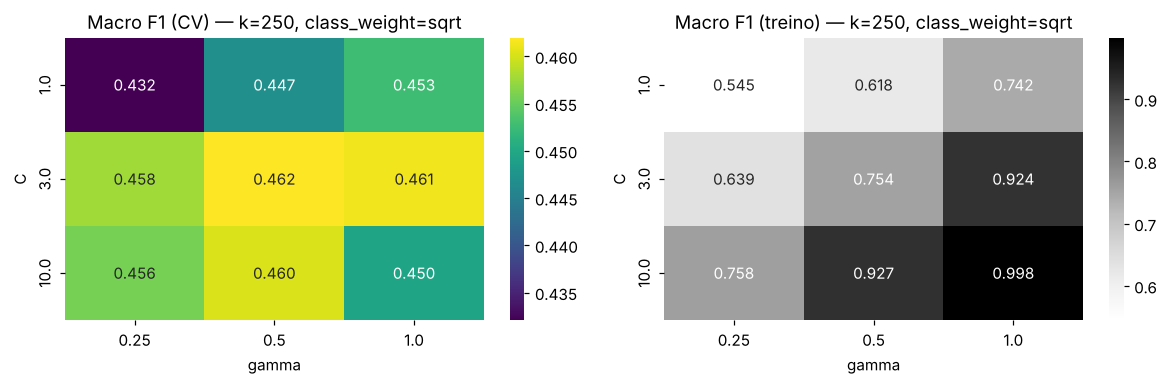

In [10]:
# C x gamma para o melhor (k, class_weight)
sub = res[(res["k"] == best["k"]) & (res["class_weight"] == best["class_weight"])]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, col, title, cmap in [(axes[0], "CV", "Macro F1 (CV)", "viridis"),
                             (axes[1], "treino", "Macro F1 (treino)", "Greys")]:
    sns.heatmap(sub.pivot(index="C", columns="gamma", values=col), annot=True, fmt=".3f", cmap=cmap, ax=ax)
    ax.set_title(f"{title} — k={best['k']}, class_weight={best['class_weight']}")
plt.tight_layout(); plt.show()

**Leitura.**
* **Melhor da grelha:** k=250, C=3, gamma=0.5, com CV 0.4619 ± 0.0070 (EP).
* **Extensão:** k=250 ficou na ponta da grelha. A extensão testou k=450, que foi pior, e o ótimo ficou no interior.
* **Superfície plana:** as 9 melhores combinações estão entre 0.456 e 0.462, a menos de um erro-padrão umas das outras, com k=150 e k=250 misturados. Com 3 folds, a grelha não as distingue, e por isso a escolha é refeita na secção 5 com CV repetida.
* **Reprodutibilidade:** os intervalos da grelha vêm de explorações preliminares que não estão neste notebook (ver nota no início da secção).

## 5. Seleção do modelo

Na grelha (3 folds), várias combinações ficam separadas por menos de um erro-padrão. Escolher o máximo de
muitas estimativas com ruído dá um CV **enviesado para cima**. Para reduzir o ruído na escolha:

1. as combinações a menos de 1 erro-padrão simples do melhor CV da grelha (critério de **pré-seleção**,
   ≈ 0.004) são reavaliadas com **validação cruzada repetida** (3 folds × 3 repetições), nos mesmos 9 folds
   para todas;
2. à volta da melhor dessas combinações faz-se uma **afinação fina** (`k` ± 50, `C` ×/÷ 1.5, `gamma` ×/÷ 1.4),
   também com CV repetida;
3. o modelo final **não** é o máximo do CV repetido: escolher o máximo de dezenas de estimativas nos mesmos
   folds dá um valor enviesado para cima e um ponto que pode cair na ponta da vizinhança por ruído. Toma-se a
   **zona de empate** — combinações a menos de 1 EP (Nadeau & Bengio) do melhor CV repetido — e escolhe-se a
   combinação **mais próxima do centro dessa zona** (centróide de log k, log C, log gamma, cada eixo
   padronizado). Numa superfície plana, o centro é o ponto mais afastado das fronteiras onde o desempenho cai.

In [11]:
def to_params(row):
    k = row["k"] if row["k"] == "all" else int(row["k"])
    cw = None if row["class_weight"] == "None" else row["class_weight"]
    return dict(k=k, C=float(row["C"]), gamma_mult=float(row["gamma"]), class_weight=cw)

tag_rep = f"{tag}_{fingerprint(repr(cv_rep), nb_se)}"      # a CV repetida também entra na chave
REP_PATH = f"grid_cache/{tag_rep}_repetido.csv"
rep_cache = pd.read_csv(REP_PATH, dtype={"k": str}, keep_default_na=False) if os.path.exists(REP_PATH) else pd.DataFrame()

def eval_rep(k, C, gamma, cw, grid_cv=np.nan):
    # CV repetida (3 x 3) de uma combinação, com cache em disco
    global rep_cache
    key = (str(k), float(C), float(gamma), str(cw))
    if len(rep_cache):
        hit = rep_cache[(rep_cache["k"] == key[0]) & np.isclose(rep_cache["C"].astype(float), key[1])
                        & np.isclose(rep_cache["gamma"].astype(float), key[2]) & (rep_cache["class_weight"] == key[3])]
        if len(hit):
            return hit.iloc[0].to_dict()
    k = k if str(k) == "all" else int(k)
    r = cross_validate(make_svm(**STRUCT, k=k, C=C, gamma_mult=gamma, class_weight=None if cw == "None" else cw),
                       X_tr, y_tr, cv=cv_rep, scoring="f1_macro", return_train_score=True, n_jobs=N_JOBS)
    out = {"k": key[0], "C": key[1], "gamma": key[2], "class_weight": key[3],
           "CV grelha": grid_cv, "treino": r["train_score"].mean(), "CV rep": r["test_score"].mean(),
           "CV rep EP": nb_se(r["test_score"]),
           "folds": " ".join(f"{v:.6f}" for v in r["test_score"])}
    rep_cache = pd.concat([rep_cache, pd.DataFrame([out])], ignore_index=True)
    rep_cache.to_csv(REP_PATH, index=False)
    return out

def as_table(rows):
    t = pd.DataFrame(rows)
    for c in ["C", "gamma", "CV grelha", "treino", "CV rep", "CV rep EP"]:
        t[c] = pd.to_numeric(t[c], errors="coerce")      # "" (lido do cache) -> NaN
    return t.drop_duplicates(["k", "C", "gamma", "class_weight"]).sort_values("CV rep", ascending=False).reset_index(drop=True)

# 1) candidatas da grelha
t = time.time()
cand = res[res["CV"] >= best["CV"] - best["CV_se"]]
rep = as_table([eval_rep(r["k"], r["C"], r["gamma"], r["class_weight"], r["CV"]) for _, r in cand.iterrows()])
print(f"1) {len(cand)} candidatas da grelha reavaliadas ({(time.time() - t) / 60:.1f} min)")
display(rep[["k", "C", "gamma", "class_weight", "treino", "CV grelha", "CV rep", "CV rep EP"]])
top = rep.iloc[0]
g_row = rep[(rep["k"] == best["k"]) & np.isclose(rep["C"], best["C"]) & np.isclose(rep["gamma"], best["gamma"])
            & (rep["class_weight"] == best["class_weight"])].iloc[0]
print(f"Otimismo da seleção na grelha: vencedor da grelha tinha CV {best['CV']:.4f}; em CV repetida tem {g_row['CV rep']:.4f}")

# 2) afinação fina à volta da melhor
t = time.time()
k0 = int(top["k"])
fine = [eval_rep(k, C, g, top["class_weight"])
        for k in sorted({max(50, k0 - 50), k0, k0 + 50})
        for C in [top["C"] / 1.5, top["C"], top["C"] * 1.5]
        for g in [top["gamma"] / 1.4, top["gamma"], top["gamma"] * 1.4]]
fine = as_table(fine)
print(f"2) afinação fina: {len(fine)} combinações ({(time.time() - t) / 60:.1f} min)")
display(fine[["k", "C", "gamma", "class_weight", "treino", "CV rep", "CV rep EP"]].head(10))

# 3) modelo final = combinação mais central da zona de empate (a menos de 1 EP N&B do melhor CV repetido)
allrep = as_table(pd.concat([rep, fine]).to_dict("records"))
row_max = allrep.iloc[0]
tied = allrep[(allrep["CV rep"] >= row_max["CV rep"] - row_max["CV rep EP"])
              & (allrep["class_weight"] == row_max["class_weight"])].copy()
Z = np.log(np.c_[tied["k"].astype(float), tied["C"], tied["gamma"]])
Z = (Z - Z.mean(0)) / np.where(Z.std(0) > 0, Z.std(0), 1)
tied["dist_centro"] = np.sqrt((Z ** 2).sum(1))
row_F = tied.sort_values(["dist_centro", "CV rep"], ascending=[True, False]).iloc[0]
FINAL_PARAMS = to_params(row_F)
folds_F = np.array(row_F["folds"].split(), dtype=float)
folds_max = np.array(row_max["folds"].split(), dtype=float)
print(f"\nMáximo do CV repetido: k={row_max['k']}, C={row_max['C']:.3g}, gamma={row_max['gamma']:.3g} -> "
      f"{row_max['CV rep']:.4f} ± {row_max['CV rep EP']:.4f}")
print(f"Zona de empate (< 1 EP N&B do máximo): {len(tied)} de {len(allrep)} combinações | "
      f"k {[int(v) for v in sorted(tied['k'].astype(int).unique())]}, C {tied['C'].min():.3g}–{tied['C'].max():.3g}, "
      f"gamma {tied['gamma'].min():.3g}–{tied['gamma'].max():.3g}")
print(f"\nModelo final (centro da zona): {FINAL_PARAMS}")
print(f"CV repetido = {row_F['CV rep']:.4f} ± {row_F['CV rep EP']:.4f} (EP) | treino {row_F['treino']:.4f}")
d = folds_max - folds_F
print(f"Diferença máximo − final: {d.mean():+.4f} ± {nb_se(d):.4f} (EP N&B, emparelhada)")

# Posição do modelo final dentro do intervalo de valores avaliados (grelha + vizinhança fina)
for col in ["k", "C", "gamma"]:
    vals = np.sort(allrep[col].astype(float).unique())
    v = float(row_F[col])
    pos = "ponta" if (np.isclose(v, vals[0]) or np.isclose(v, vals[-1])) else "interior"
    print(f"  {col:6s} = {v:<8.4g} -> {pos} dos valores avaliados")

1) 9 candidatas da grelha reavaliadas (0.0 min)


,k,C,gamma,class_weight,treino,CV grelha,CV rep,CV rep EP
0,150,10.0000,0.2500,sqrt,0.6881,0.4569,0.4573,0.0045
1,250,3.0000,0.5000,sqrt,0.7520,0.4619,0.4569,0.0092
2,150,3.0000,0.5000,sqrt,0.6860,0.4563,0.4558,0.0076
3,250,10.0000,0.2500,sqrt,0.7582,0.4557,0.4543,0.0073
4,250,3.0000,1.0000,sqrt,0.9226,0.4613,0.4543,0.0076
5,250,3.0000,0.2500,sqrt,0.6387,0.4577,0.4541,0.0072
6,150,3.0000,1.0000,sqrt,0.8453,0.4568,0.4535,0.0076
7,250,10.0000,0.5000,sqrt,0.9245,0.4603,0.4508,0.0085
8,150,1.0000,1.0000,sqrt,0.6764,0.4559,0.4501,0.0075


Otimismo da seleção na grelha: vencedor da grelha tinha CV 0.4619; em CV repetida tem 0.4569
2) afinação fina: 27 combinações (0.0 min)


,k,C,gamma,class_weight,treino,CV rep,CV rep EP
0,200,6.6667,0.2500,sqrt,0.6849,0.4603,0.0062
1,200,15.0000,0.1786,sqrt,0.7072,0.4599,0.0043
2,200,10.0000,0.1786,sqrt,0.6701,0.4597,0.0059
3,200,10.0000,0.2500,sqrt,0.7268,0.4590,0.0050
4,200,6.6667,0.3500,sqrt,0.7481,0.4586,0.0030
5,200,6.6667,0.1786,sqrt,0.6392,0.4584,0.0072
6,150,6.6667,0.3500,sqrt,0.7085,0.4575,0.0046
7,150,10.0000,0.2500,sqrt,0.6881,0.4573,0.0045
8,200,15.0000,0.2500,sqrt,0.7762,0.4573,0.0050
9,150,10.0000,0.3500,sqrt,0.7561,0.4573,0.0051



Máximo do CV repetido: k=200, C=6.67, gamma=0.25 -> 0.4603 ± 0.0062
Zona de empate (< 1 EP N&B do máximo): 21 de 35 combinações | k [150, 200, 250], C 3–15, gamma 0.179–1

Modelo final (centro da zona): {'k': 200, 'C': 6.666666666666667, 'gamma_mult': 0.25, 'class_weight': 'sqrt'}
CV repetido = 0.4603 ± 0.0062 (EP) | treino 0.6849
Diferença máximo − final: +0.0000 ± 0.0000 (EP N&B, emparelhada)
  k      = 200      -> interior dos valores avaliados
  C      = 6.667    -> interior dos valores avaliados
  gamma  = 0.25     -> interior dos valores avaliados


**Leitura.**
* **Otimismo da seleção.** Reavaliado com CV repetida, o vencedor da grelha desce de 0.4619 para 0.4569. As 9 candidatas ficam entre 0.450 e 0.457.
* **Zona de empate.** O máximo do CV repetido é k=200, C≈6.67, gamma=0.25 (0.4603 ± 0.0062). 21 das 35 combinações avaliadas ficam a menos de um EP dele, com k entre 150 e 250, C entre 3 e 15 e gamma entre 0.18 e 1. É uma zona larga e plana.
* **Modelo final.** O centro da zona de empate coincide com o máximo: k=200, C≈6.67, gamma=0.25, `sqrt`. Fica no interior dos valores avaliados nos três parâmetros, por isso o ótimo deixa de estar numa ponta.
* **CV otimista.** Como o ponto escolhido é também o máximo de 35 estimativas, o CV repetido de 0.4603 mantém algum otimismo de seleção. A grelha mostra a ordem de grandeza desse otimismo: −0.005 na reavaliação do seu vencedor. O holdout (secção 8) é a estimativa sem esse viés.

## 6. Ablação — contributo de cada componente

Partindo do SVM com o pré-processamento da secção 1 e parâmetros por omissão (`C=1`, `gamma=scale`,
todas as features), acrescenta-se uma componente de cada vez. Cada configuração é comparada com a sua
**referência** (o passo anterior) por diferenças emparelhadas:

* **CV** — mesmos 9 folds (3 × 3 repetições) para todas as configurações; Δ = média das diferenças fold a fold ±
  EP com a correção de Nadeau & Bengio;
* **holdout** — Δ do Macro F1 com IC 95% por bootstrap emparelhado (mesmas reamostragens).

Um passo só tem efeito demonstrado quando o IC da diferença no holdout exclui o zero (e o Δ CV é maior que ~2 EP).

In [12]:
base = dict(k="all", corr=None, scale_all=False, C=1.0, gamma_mult=1.0, class_weight=None)
N_BASE, N_BAL, N_SQRT = "base (pré-proc. + SVM por omissão)", "+ class_weight='balanced'", "+ class_weight='sqrt'"
N_K, N_KS = "+ SelectKBest(k=250)", f"+ SelectKBest(k=250) + estrutura {STRUCT}"
N_KSW, N_F = "+ SelectKBest(k=250) + estrutura + 'sqrt'", "+ afinação (modelo final)"
ablation = {  # nome: (parâmetros, referência)
    N_BASE: (base, None),
    N_BAL: ({**base, "class_weight": "balanced"}, N_BASE),
    N_SQRT: ({**base, "class_weight": "sqrt"}, N_BASE),
    N_K: ({**base, "k": 250}, N_BASE),
    N_KS: ({**base, **STRUCT, "k": 250}, N_K),
    N_KSW: ({**base, **STRUCT, "k": 250, "class_weight": "sqrt"}, N_KS),
    N_F: ({**STRUCT, **FINAL_PARAMS}, N_KSW),
}
rows, folds, abl_pred = [], {}, {}
for name, (p, ref) in ablation.items():
    t = time.time()
    folds[name] = cross_validate(make_svm(**p), X_tr, y_tr, cv=cv_rep, scoring="f1_macro", n_jobs=N_JOBS)["test_score"]
    abl_pred[name] = make_svm(**p).fit(X_tr, y_tr).predict(X_ho)
    row = {"configuração": name, "referência": ref or "—", "CV": folds[name].mean(), "holdout": macro_f1(y_ho, abl_pred[name])}
    if ref is not None:
        dcv = folds[name] - folds[ref]
        dho = bootstrap_diff(y_ho, abl_pred[name], abl_pred[ref])
        row.update({"Δ CV": dcv.mean(), "Δ CV EP (N&B)": nb_se(dcv), "Δ CV / EP": dcv.mean() / nb_se(dcv),
                    "Δ holdout": dho[0], "Δ IC95_inf": dho[1], "Δ IC95_sup": dho[2],
                    "IC exclui 0": bool(dho[1] > 0 or dho[2] < 0)})
    row["tempo_s"] = time.time() - t
    rows.append(row)
abl = pd.DataFrame(rows).set_index("configuração")
display(abl)

tot = bootstrap_diff(y_ho, abl_pred[N_F], abl_pred[N_BASE])
dcv = folds[N_F] - folds[N_BASE]
print(f"Total (modelo final − base): Δ CV {dcv.mean():+.4f} ± {nb_se(dcv):.4f} (EP N&B) | "
      f"Δ holdout {fmt_ci(tot)}")

,referência,CV,holdout,tempo_s,Δ CV,Δ CV EP (N&B),Δ CV / EP,Δ holdout,Δ IC95_inf,Δ IC95_sup,IC exclui 0
configuração,,,,,,,,,,,
base (pré-proc. + SVM por omissão),—,0.4073,0.4001,142.8672,NaN,NaN,NaN,NaN,NaN,NaN,NaN
+ class_weight='balanced',base (pré-proc. + SVM por omissão),0.4292,0.4316,147.7316,0.0219,0.0042,5.1650,0.0315,0.0134,0.0503,True
+ class_weight='sqrt',base (pré-proc. + SVM por omissão),0.4303,0.4241,157.9743,0.0229,0.0041,5.5588,0.0240,0.0091,0.0403,True
+ SelectKBest(k=250),base (pré-proc. + SVM por omissão),0.4240,0.4362,49.8953,0.0166,0.0060,2.7842,0.0361,0.0143,0.0582,True
"+ SelectKBest(k=250) + estrutura {'corr': 0.9, 'scale_all': False}",+ SelectKBest(k=250),0.4277,0.4432,53.8554,0.0037,0.0060,0.6173,0.0071,-0.0107,0.0255,False
+ SelectKBest(k=250) + estrutura + 'sqrt',"+ SelectKBest(k=250) + estrutura {'corr': 0.9,...",0.4506,0.4532,56.2302,0.0230,0.0048,4.8294,0.0099,-0.0057,0.0257,False
+ afinação (modelo final),+ SelectKBest(k=250) + estrutura + 'sqrt',0.4603,0.4610,45.7214,0.0096,0.0064,1.4978,0.0078,-0.0100,0.0272,False


Total (modelo final − base): Δ CV +0.0529 ± 0.0078 (EP N&B) | Δ holdout 0.0609 [0.0370, 0.0849]


**Leitura (diferenças emparelhadas, CV repetida 3×3, EP de Nadeau & Bengio).**
* **Contributos demonstrados (Δ CV / EP > 2,7; IC do holdout exclui 0):**
  * pesos das classes sobre o SVM base: `balanced` +0.022, `sqrt` +0.023;
  * `SelectKBest(k=250)`: +0.017.
* **Sem efeito demonstrado:**
  * filtro de correlação: +0.0037 (0.6 EP) e IC do holdout inclui 0;
  * afinação de C, gamma e k: +0.0096 (1.5 EP) e IC do holdout inclui 0.
* **Pesos `sqrt` sobre o pipeline com seleção:** +0.023 em CV (4.8 EP), mas no holdout +0.010 com um IC que inclui 0. A secção 7 repete esta comparação com os hiperparâmetros do modelo final.
* **Total (modelo final − base):** +0.053 ± 0.008 em CV e +0.061 [0.037, 0.085] no holdout. O ganho demonstrado vem dos pesos das classes no SVM base e da seleção de features.

## 7. Pesos das classes — efeito por classe

Com os restantes hiperparâmetros do modelo final fixos, as três opções de `class_weight` são comparadas com
`None` por diferenças emparelhadas em **CV repetida** (mesmos 9 folds, EP de Nadeau & Bengio) e no **holdout**
(IC 95% por bootstrap emparelhado), e é mostrado o F1 por classe no holdout.

,CV rep,Δ CV vs None,Δ CV EP (N&B),holdout,IC95_inf,IC95_sup,Δ holdout vs None,Δ IC95_inf,Δ IC95_sup
class_weight,,,,,,,,,
None,0.4497,0.0000,0.0000,0.4596,0.4353,0.4817,0.0000,0.0000,0.0000
sqrt,0.4603,0.0105,0.0045,0.4610,0.4378,0.4829,0.0013,-0.0121,0.0159
balanced,0.4563,0.0066,0.0049,0.4479,0.4258,0.4707,-0.0117,-0.0282,0.0052


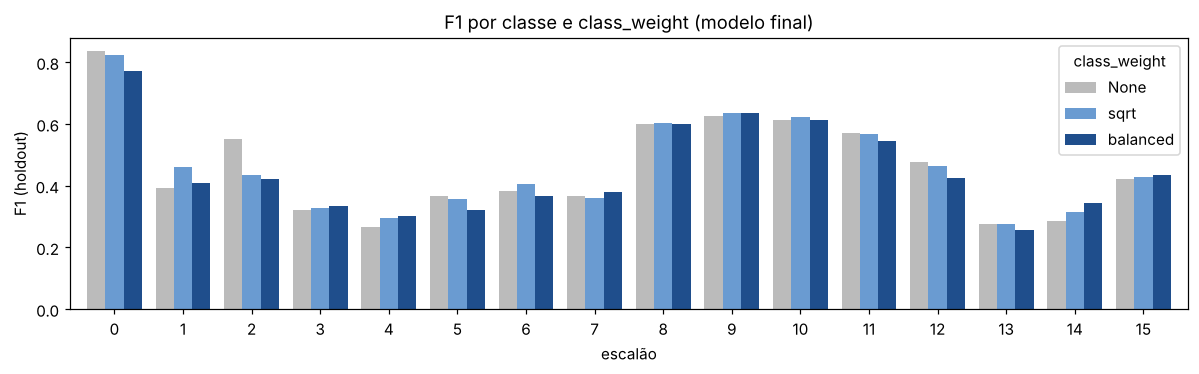

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
None,0.8372,0.3929,0.5500,0.3200,0.2651,0.3657,0.3842,0.3680,0.5989,0.6263,0.6147,0.5721,0.4766,0.2756,0.2845,0.4222
sqrt,0.8235,0.4595,0.4336,0.3273,0.2951,0.3564,0.4048,0.3609,0.6033,0.6350,0.6218,0.5672,0.4653,0.2774,0.3150,0.4293
balanced,0.7711,0.4096,0.4234,0.3333,0.3030,0.3226,0.3654,0.3801,0.6006,0.6368,0.6140,0.5459,0.4245,0.2572,0.3431,0.4356


In [13]:
per_class, cw_rows, cw_pred, cw_folds = {}, [], {}, {}
for cw in [None, "sqrt", "balanced"]:
    cw_folds[str(cw)] = f = cross_validate(make_svm(**STRUCT, **{**FINAL_PARAMS, "class_weight": cw}), X_tr, y_tr,
                                           cv=cv_rep, scoring="f1_macro", n_jobs=N_JOBS)["test_score"]
    dcv = f - cw_folds["None"]
    m = make_svm(**STRUCT, **{**FINAL_PARAMS, "class_weight": cw}).fit(X_tr, y_tr)
    cw_pred[str(cw)] = p = m.predict(X_ho)
    per_class[str(cw)] = f1_score(y_ho, p, average=None)
    ci = bootstrap_ci(y_ho, p)
    dn = bootstrap_diff(y_ho, p, cw_pred["None"])
    cw_rows.append({"class_weight": str(cw), "CV rep": f.mean(),
                    "Δ CV vs None": dcv.mean(), "Δ CV EP (N&B)": nb_se(dcv) if dcv.any() else 0.0,
                    "holdout": ci[0], "IC95_inf": ci[1], "IC95_sup": ci[2],
                    "Δ holdout vs None": dn[0], "Δ IC95_inf": dn[1], "Δ IC95_sup": dn[2]})
per_class = pd.DataFrame(per_class, index=sorted(y.unique()))
display(pd.DataFrame(cw_rows).set_index("class_weight"))

fig, ax = plt.subplots(figsize=(11, 3.5))
per_class.plot.bar(ax=ax, rot=0, color=["#BBBBBB", "#6A9BD1", "#1F4E8C"], width=0.8)
ax.set_xlabel("escalão"); ax.set_ylabel("F1 (holdout)"); ax.set_title("F1 por classe e class_weight (modelo final)")
ax.legend(title="class_weight"); plt.tight_layout(); plt.show()
per_class.T

**Leitura.**

**Efeito global:**

| `class_weight` | Δ CV vs `None` | em EP (N&B) | Δ holdout vs `None` |
|---|---|---|---|
| `sqrt` | +0.0105 ± 0.0045 | 2.3 | +0.0013 [−0.012, +0.016] |
| `balanced` | +0.0066 | 1.3 | −0.012 (IC inclui 0) |

* **`sqrt`:** a evidência a favor em CV é moderada e o holdout não a confirma.
* **`balanced`:** não tem efeito demonstrado.
* Com os hiperparâmetros do modelo final, **os pesos não têm benefício provado**. `sqrt` mantém-se porque tem o melhor CV e não piora o holdout, mas não é apresentado como um contributo para o desempenho. O efeito claro dos pesos aparece só no SVM base, sem seleção de features (secção 6).

**Por classe,** os pesos trocam recall entre classes:
* **Ganham:** as classes pequenas dos extremos (escalão 1: 0.39 → 0.46 com `sqrt`; escalões 14 e 15).
* **Perdem:** os escalões 0, 2 e 12, sobretudo com `balanced`.

## 8. Avaliação final no holdout

In [14]:
model = make_svm(**STRUCT, **FINAL_PARAMS).fit(X_tr, y_tr)
p_ho, p_tr = model.predict(X_ho), model.predict(X_tr)
ci = bootstrap_ci(y_ho, p_ho)
summary = pd.Series({
    "Macro F1 treino": macro_f1(y_tr, p_tr),
    "Macro F1 CV repetido": row_F["CV rep"],
    "Macro F1 holdout": ci[0], "holdout IC95_inf": ci[1], "holdout IC95_sup": ci[2],
    "gap treino−holdout": macro_f1(y_tr, p_tr) - ci[0],
    "accuracy holdout": accuracy_score(y_ho, p_ho),
    "acc_±1 holdout": np.mean(np.abs(np.asarray(y_ho) - p_ho) <= 1),
}, name="modelo final")
display(summary.to_frame())
print(classification_report(y_ho, p_ho, digits=3))

,modelo final
Macro F1 treino,0.6629
Macro F1 CV repetido,0.4603
Macro F1 holdout,0.4610
holdout IC95_inf,0.4378
holdout IC95_sup,0.4829
gap treino−holdout,0.2019
accuracy holdout,0.4679
acc_±1 holdout,0.8454


              precision    recall  f1-score   support

           0      0.795     0.854     0.824        41
           1      0.425     0.500     0.459        34
           2      0.492     0.388     0.434        80
           3      0.300     0.360     0.327        75
           4      0.290     0.300     0.295        90
           5      0.336     0.380     0.356       129
           6      0.421     0.390     0.405       172
           7      0.383     0.341     0.361       173
           8      0.594     0.613     0.603       181
           9      0.645     0.626     0.635       203
          10      0.615     0.629     0.622       213
          11      0.588     0.548     0.567       208
          12      0.421     0.520     0.465       200
          13      0.297     0.261     0.277       165
          14      0.323     0.308     0.315       130
          15      0.446     0.414     0.429        99

    accuracy                          0.468      2193
   macro avg      0.461   

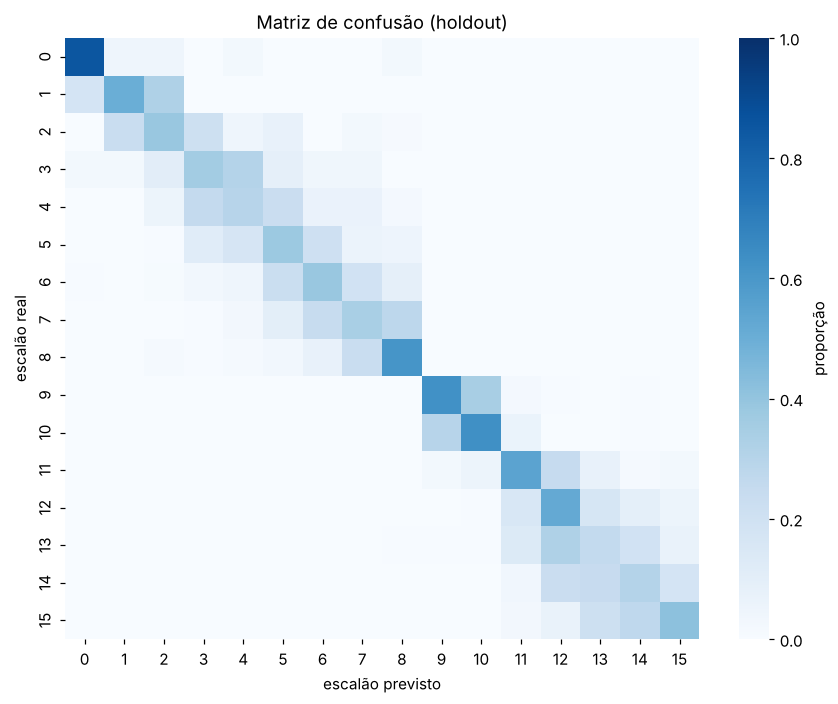

In [15]:
# Matriz de confusão normalizada por linha (proporção de cada escalão real)
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_ho, p_ho, normalize="true")
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(cm, cmap="Blues", vmin=0, vmax=1, ax=ax, cbar_kws={"label": "proporção"},
            xticklabels=sorted(y.unique()), yticklabels=sorted(y.unique()))
ax.set_xlabel("escalão previsto"); ax.set_ylabel("escalão real"); ax.set_title("Matriz de confusão (holdout)")
plt.tight_layout(); plt.show()

### 8.1 Distribuição das previsões por escalão

Compara-se o número de previsões de cada escalão com o número real, fora da amostra (previsões *out-of-fold*
no treino e holdout). Testa-se depois uma **correção de viés por escalão**: somar à função de decisão um
deslocamento por classe, ajustado nas previsões *out-of-fold* para que as contagens previstas igualem a
distribuição real (ajuste iterativo das contagens). A correção só é adotada se melhorar o Macro F1 numa
validação do próprio ajuste (ajusta-se em 2/3 das previsões *out-of-fold* e avalia-se no 1/3 restante,
3 partições × 3 repetições), e **não** pelo holdout.

In [16]:
from sklearn.model_selection import cross_val_predict
yt, yh = np.asarray(y_tr), np.asarray(y_ho)
K = len(np.unique(yt))
classes = np.sort(np.unique(yt))

def match_offsets(D, target_counts, iters=5000, eta=0.05, tol=0.02):
    # deslocamentos por classe que igualam as contagens previstas (argmax) às contagens alvo, no mesmo
    # conjunto D a que são ajustados (passo decrescente). Devolve também se convergiu:
    # |previsto − alvo| ≤ max(2, 2%) em todas as classes; se não convergir, devolve o melhor ponto visitado.
    target = np.asarray(target_counts, dtype=float)
    assert np.isclose(target.sum(), len(D)), "o alvo tem de ter o mesmo total que D"
    ok = lambda c: bool(np.all(np.abs(c - target) <= np.maximum(2, tol * target)))
    b = np.zeros(D.shape[1]); best_b, best_err = b.copy(), np.inf
    for t in range(iters):
        c = np.bincount((D + b).argmax(1), minlength=D.shape[1])
        if ok(c):
            return b, True
        err = np.max(np.abs(c - target) / np.maximum(target, 1))
        if err < best_err:
            best_b, best_err = b.copy(), err
        b += eta / np.sqrt(1 + t / 50) * (np.log(target + 0.5) - np.log(c + 0.5))
    return best_b, ok(np.bincount((D + best_b).argmax(1), minlength=D.shape[1]))

t = time.time()
D_oof = cross_val_predict(make_svm(**STRUCT, **FINAL_PARAMS), X_tr, y_tr, cv=cv,
                          method="decision_function", n_jobs=N_JOBS)
D_ho = model.decision_function(X_ho)
p_oof = classes[D_oof.argmax(1)]
print(f"decisões out-of-fold: {time.time() - t:.0f}s")

counts = pd.DataFrame({
    "real (OOF)": np.bincount(yt, minlength=K), "previsto (OOF)": np.bincount(p_oof, minlength=K),
    "real (holdout)": np.bincount(yh, minlength=K), "previsto (holdout)": np.bincount(p_ho, minlength=K),
}, index=pd.Index(classes, name="escalão"))
counts["excesso OOF (%)"] = 100 * (counts["previsto (OOF)"] / counts["real (OOF)"] - 1)
counts["excesso holdout (%)"] = 100 * (counts["previsto (holdout)"] / counts["real (holdout)"] - 1)
display(counts.round(1))

cm_oof = pd.DataFrame(confusion_matrix(yt, p_oof)[11:15, 11:15], index=[f"real {c}" for c in classes[11:15]],
                      columns=[f"prev {c}" for c in classes[11:15]])
print("Confusões entre os escalões 11-14 (OOF):"); display(cm_oof)

# Validação da correção de viés: ajuste em 2/3 das decisões OOF, avaliação no 1/3 restante
# (os desvios são ajustados em D_oof[a] com as contagens reais de a; aplicados a b, onde a distribuição é a mesma)
gains, conv = [], []
for rs in range(3):
    for a, b in StratifiedKFold(3, shuffle=True, random_state=rs).split(D_oof, yt):
        off, ok = match_offsets(D_oof[a], np.bincount(yt[a], minlength=K))
        conv.append(ok)
        gains.append(macro_f1(yt[b], classes[(D_oof[b] + off).argmax(1)]) - macro_f1(yt[b], classes[D_oof[b].argmax(1)]))
gains = np.array(gains)
OFFSETS, ok_full = match_offsets(D_oof, np.bincount(yt, minlength=K))
print(f"Ajuste dos desvios convergiu: {sum(conv)}/{len(conv)} ajustes internos | ajuste completo: {ok_full}")
p_ho_off = classes[(D_ho + OFFSETS).argmax(1)]
USE_OFFSETS = gains.mean() > 2 * nb_se(gains, test_train_ratio=1 / 2)
print(f"Ganho da correção (validação do ajuste): {gains.mean():+.4f} ± {nb_se(gains):.4f} (EP N&B)")
print(f"Holdout (só verificação): {fmt_ci(bootstrap_diff(y_ho, p_ho_off, p_ho))} | "
      f"escalões 12/13 previstos: {np.bincount(p_ho_off, minlength=K)[[12, 13]]} (real {np.bincount(yh, minlength=K)[[12, 13]]})")
print("Correção com ganho > 2 EP:", USE_OFFSETS, "-> a submissão usa as previsões sem correção")

decisões out-of-fold: 15s


,real (OOF),previsto (OOF),real (holdout),previsto (holdout),excesso OOF (%),excesso holdout (%)
escalão,,,,,,
0,166,185,41,44,11.4000,7.3000
1,138,127,34,40,-8.0000,17.6000
2,319,301,80,63,-5.6000,-21.3000
3,302,342,75,90,13.2000,20.0000
4,359,350,90,93,-2.5000,3.3000
5,518,477,129,146,-7.9000,13.2000
6,687,708,172,159,3.1000,-7.6000
7,689,684,173,154,-0.7000,-11.0000
8,724,729,181,187,0.7000,3.3000


Confusões entre os escalões 11-14 (OOF):


,prev 11,prev 12,prev 13,prev 14
real 11,431,234,54,29
real 12,237,318,141,64
real 13,106,193,181,109
real 14,43,98,114,156


Ajuste dos desvios convergiu: 9/9 ajustes internos | ajuste completo: True
Ganho da correção (validação do ajuste): -0.0009 ± 0.0033 (EP N&B)


Holdout (só verificação): -0.0095 [-0.0162, -0.0024] | escalões 12/13 previstos: [211 184] (real [200 165])
Correção com ganho > 2 EP: False -> a submissão usa as previsões sem correção


**Leitura.**

**Distribuição das previsões.** O excesso de previsões no escalão 12 e a falta no 13 aparecem também out-of-fold (+11% e −17%). O escalão 3 também é sobre-previsto (+13% OOF). Os empates da votação já são resolvidos pela confiança (`break_ties=True`), por isso este desequilíbrio não vem do desempate.

**Causa: confusão real entre 12 e 13.** A confusão entre os dois escalões existe **nos dois sentidos**, ao nível da matriz de confusão OOF:

| real | previsto | casos |
|---|---|---|
| 13 | 12 | 193 |
| 12 | 13 | 141 |

Só 181 dos 658 casos reais do escalão 13 são previstos como 13. Os perfis dos dois escalões sobrepõem-se, e os casos ambíguos vão mais para o 12, que tem mais casos.

**Correção das contagens por desvios aditivos.** Põe as contagens previstas iguais às reais, e o ajuste convergiu em todos os casos (9/9 internos e no ajuste completo).
* **Não melhora a Macro F1:** −0.0009 ± 0.0033 na validação interna e −0.0095 [−0.016, −0.002] no holdout.
* **Contagens corrigidas mas não mais acertos:** no holdout, os escalões 12 e 13 passam a 211 e 184 previsões, contra 200 e 165 reais.
* **Porquê:** mover casos ambíguos entre vizinhos não os classifica melhor.

A correção **não é usada** na submissão. O desequilíbrio das contagens é um limite do modelo, não um enviesamento corrigível.

learning curve: 42s


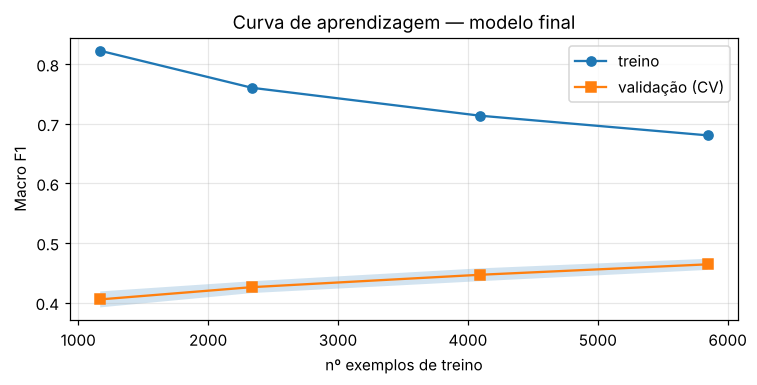

,treino,CV
n_treino,,
1169,0.8222,0.4052
2338,0.7601,0.4258
4092,0.7134,0.4465
5846,0.6803,0.4640


In [17]:
# Curva de aprendizagem do modelo final (desempenho fora da amostra em função do nº de exemplos)
t = time.time()
sizes, lc_tr, lc_va = learning_curve(make_svm(**STRUCT, **FINAL_PARAMS), X_tr, y_tr,
                                     train_sizes=[0.2, 0.4, 0.7, 1.0], cv=cv, scoring="f1_macro", n_jobs=N_JOBS)
print(f"learning curve: {time.time() - t:.0f}s")
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(sizes, lc_tr.mean(1), "o-", label="treino")
ax.plot(sizes, lc_va.mean(1), "s-", label="validação (CV)")
ax.fill_between(sizes, lc_va.mean(1) - lc_va.std(1), lc_va.mean(1) + lc_va.std(1), alpha=.2)
ax.set_xlabel("nº exemplos de treino"); ax.set_ylabel("Macro F1"); ax.legend(); ax.grid(alpha=.3)
ax.set_title("Curva de aprendizagem — modelo final"); plt.tight_layout(); plt.show()
pd.DataFrame({"treino": lc_tr.mean(1), "CV": lc_va.mean(1)}, index=pd.Index(sizes, name="n_treino"))

**Leitura.**
* **Sobreajuste moderado:** o F1 de treino é 0.66 e o de holdout 0.46. Esta diferença é habitual num SVM RBF com C>1, que ajusta fronteiras locais aos exemplos de treino. Regularizar mais (C menor) ficou equivalente ou pior na secção 5.
* **Curva de aprendizagem:** a CV sobe de forma consistente com o número de exemplos (0.405 → 0.464) e o treino desce (0.82 → 0.68). As curvas ainda não convergiram. Isto justifica treinar o modelo da submissão com **todos** os dados de treino (secção 9).
* **Acerto aproximado:** 85% das previsões do holdout estão a ±1 escalão do real. Os erros são quase todos entre escalões vizinhos.

## 9. Modelo final e submissão Kaggle

Reajuste do modelo final com **todos** os dados de treino (deteção das colunas numéricas incluída) e geração
de `submission_svm_final.csv`. O formato é validado contra o ficheiro de exemplo da competição.

In [18]:
num_cols_full = detect_numeric_columns(train.drop(columns=DROP_COLS + [TARGET]))
X_full = clean(train, num_cols_full)
X_test = clean(test, num_cols_full)[X_full.columns]
print("Colunas numéricas iguais às da partição de treino:", num_cols_full == num_cols)

final_model = make_svm(**STRUCT, **FINAL_PARAMS, X_ref=X_full).fit(X_full, y)
pred = final_model.predict(X_test)          # sem correção de contagens (secção 8.1)

# Distribuição prevista no teste vs. esperada pela distribuição do treino
exp_test = np.bincount(y, minlength=K) / len(y) * len(X_test)
dist = pd.DataFrame({"previsto (teste)": np.bincount(pred, minlength=K), "esperado (prior do treino)": exp_test.round(0)},
                    index=pd.Index(classes, name="escalão"))
dist["excesso (%)"] = (100 * (dist["previsto (teste)"] / exp_test - 1)).round(1)
display(dist.T)

# Verificação do formato com o ficheiro de exemplo da competição
row_ids = np.arange(len(test))
if os.path.exists(SAMPLE_SUB_PATH):
    sample = pd.read_csv(SAMPLE_SUB_PATH)
    assert list(sample.columns) == ["RowId", "AGE_RANGE"], sample.columns
    assert len(sample) == len(test), (len(sample), len(test))
    assert (sample["RowId"].values == row_ids).all(), "RowId do exemplo não é 0..n-1"
    assert not sample["RowId"].isin(test["PID"]).all(), "RowId parece ser o PID"
    print(f"Formato confirmado: {len(sample)} linhas, RowId = 0..{len(sample) - 1} (índice da linha do teste, não o PID)")
else:
    print("AVISO: ficheiro de exemplo não encontrado — formato não verificado")

sub = pd.DataFrame({"RowId": row_ids, "AGE_RANGE": pred.astype(int)})
sub.to_csv("submission_svm_final.csv", index=False)
print("submission_svm_final.csv", sub.shape, "| distribuição:", sub["AGE_RANGE"].value_counts().sort_index().to_dict())

Colunas numéricas iguais às da partição de treino: True


escalão,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
previsto (teste),69.0000,55.0000,122.0000,160.0000,129.0000,184.0000,300.0000,321.0000,287.0000,355.0000,341.0000,343.0000,423.0000,216.0000,198.0000,152.0000
esperado (prior do treino),69.0000,57.0000,133.0000,126.0000,150.0000,216.0000,286.0000,287.0000,302.0000,338.0000,354.0000,347.0000,333.0000,274.0000,217.0000,165.0000
excesso (%),-0.0000,-4.1000,-8.3000,27.3000,-13.8000,-14.7000,4.7000,11.7000,-4.9000,5.0000,-3.7000,-1.1000,26.9000,-21.3000,-8.6000,-8.1000


Formato confirmado: 3655 linhas, RowId = 0..3654 (índice da linha do teste, não o PID)
submission_svm_final.csv (3655, 2) | distribuição: {0: 69, 1: 55, 2: 122, 3: 160, 4: 129, 5: 184, 6: 300, 7: 321, 8: 287, 9: 355, 10: 341, 11: 343, 12: 423, 13: 216, 14: 198, 15: 152}


## 10. Conclusões

### Modelo final
* **Pipeline:** imputação pela mediana e normalização das numéricas, one-hot das categóricas sem escalar as dummies, filtro de correlação 0.9 e `SelectKBest(k=200)`.
* **SVM RBF:** C≈6.67, gamma = 0.25/(n_features·Var(X)), `class_weight='sqrt'`, `break_ties=True`.
* **Seleção:** é a combinação mais central da zona de empate (21 de 35 combinações a menos de 1 EP N&B). Coincide com o máximo do CV repetido e fica no interior dos valores avaliados.

### Desempenho (Macro F1)

| | valor |
|---|---|
| CV repetida 3×3 | 0.4603 ± 0.0062 (EP N&B; com algum otimismo de seleção) |
| holdout | 0.4610 [0.438, 0.483] |
| accuracy ±1 escalão | 0.85 |

A partição do holdout já tinha sido usada em explorações anteriores (ver secção 2), por isso o 0.461 pode estar ligeiramente otimista. Dentro deste notebook já não há forma de o corrigir. **A única verificação independente que resta é o leaderboard público do Kaggle.**

### Contributo de cada componente
* **Demonstrados** (ablação emparelhada, EP de Nadeau & Bengio):
  * a seleção de features (`SelectKBest`);
  * os pesos das classes no SVM base.

  Juntos, dão +0.053 em CV e +0.061 no holdout sobre o SVM por omissão.
* **Sem benefício demonstrado:**
  * o filtro de correlação: +0.003 ± 0.004 em CV;
  * os pesos `sqrt` com os hiperparâmetros finais: +0.011 ± 0.005 em CV, +0.001 no holdout;
  * a afinação de C, gamma e k: +0.010 ± 0.006 em CV.

  Mantêm-se porque não pioram o desempenho, mas não são contributos provados. A superfície de hiperparâmetros é plana numa zona larga (k 150–250, C 3–15, gamma 0.18–1).

### Limites dos resultados
* **Classes difíceis:** os escalões 4, 13 e 14 ficam com F1 ≈ 0.28–0.32.
* **Confusão 12/13:** é real nos dois sentidos (193 e 141 casos OOF). O excesso de previsões no 12 não se corrige com desvios, como a secção 8.1 testou.
* **Erros entre vizinhos:** a accuracy ±1 é 0.85, por isso os erros são quase todos entre escalões adjacentes. O SVM não separa bem perfis de idades próximas com estas variáveis.
* **Sobreajuste moderado:** o F1 de treino é 0.66 e o de holdout 0.46, o que é normal num SVM RBF. A curva de aprendizagem ainda sobe, por isso o modelo da submissão é treinado com todos os dados.
* **Reprodutibilidade:** os intervalos da grelha foram definidos com explorações preliminares que não estão neste notebook.

### Submissão
`submission_svm_final.csv` — 3655 linhas, modelo reajustado com todo o treino, sem correção de contagens.